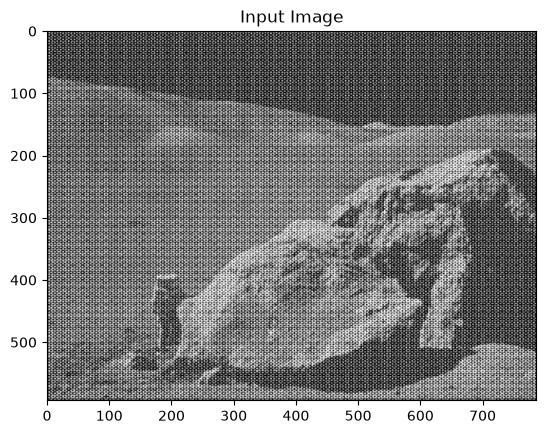

In [1]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

plt.imshow(img, cmap="gray")
plt.title("Input Image")
plt.show()

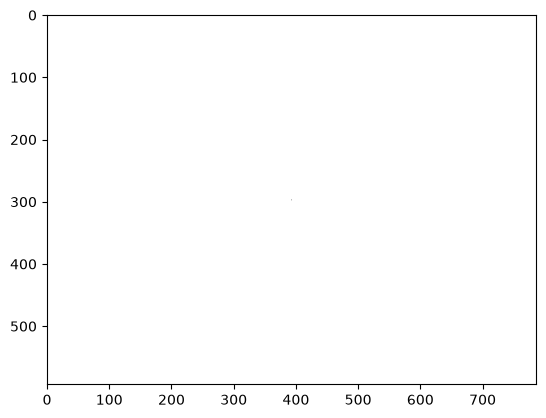

In [13]:
rows, cols = img.shape
centerX, centerY = rows // 2, cols // 2

Y, X = np.ogrid[:rows, :cols]
dist = (X - centerY)**2 + (Y - centerX)**2

sigma = 0.01
gauss = np.exp(-dist / (2 * sigma**2))
high_pass = 1 - gauss

mask_gauss = np.dstack([high_pass, high_pass])

plt.imshow(high_pass, cmap="gray")
plt.show()

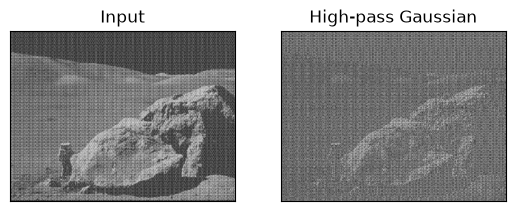

In [14]:
dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

dft_shift_hp = dft_shift * mask_gauss

f_ishift = np.fft.ifftshift(dft_shift_hp)
img_back_hp = cv.idft(f_ishift)
img_back_hp = cv.magnitude(img_back_hp[:,:,0], img_back_hp[:,:,1])

plt.subplot(121), plt.imshow(img, cmap="gray")
plt.title("Input"), plt.xticks([]), plt.yticks([])

plt.subplot(122), plt.imshow(img_back_hp, cmap="gray")
plt.title("High-pass Gaussian"), plt.xticks([]), plt.yticks([])

plt.show()

In [15]:
print("Ядро Гаусса выделяет камни, но фон видно плохо")
print("Чем больше sigms - тем хуже виден контур, поэтому 0.01 оказалось оптимальное знаечние. Если его брать меньше 0.01, то уже практически ничео не меняется")

Ядро Гаусса выделяет камни, но фон видно плохо
Чем больше sigms - тем хуже виден контур, поэтому 0.01 оказалось оптимальное знаечние. Если его брать меньше 0.01, то уже практически ничео не меняется


In [5]:
kernel_size = 15
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)

print("Ядро:")
print(kernel)

Ядро:
[[0.00444444 0.00444444 0.00444444 0.00444444 0.00444444 0.00444444
  0.00444444 0.00444444 0.00444444 0.00444444 0.00444444 0.00444444
  0.00444444 0.00444444 0.00444444]
 [0.00444444 0.00444444 0.00444444 0.00444444 0.00444444 0.00444444
  0.00444444 0.00444444 0.00444444 0.00444444 0.00444444 0.00444444
  0.00444444 0.00444444 0.00444444]
 [0.00444444 0.00444444 0.00444444 0.00444444 0.00444444 0.00444444
  0.00444444 0.00444444 0.00444444 0.00444444 0.00444444 0.00444444
  0.00444444 0.00444444 0.00444444]
 [0.00444444 0.00444444 0.00444444 0.00444444 0.00444444 0.00444444
  0.00444444 0.00444444 0.00444444 0.00444444 0.00444444 0.00444444
  0.00444444 0.00444444 0.00444444]
 [0.00444444 0.00444444 0.00444444 0.00444444 0.00444444 0.00444444
  0.00444444 0.00444444 0.00444444 0.00444444 0.00444444 0.00444444
  0.00444444 0.00444444 0.00444444]
 [0.00444444 0.00444444 0.00444444 0.00444444 0.00444444 0.00444444
  0.00444444 0.00444444 0.00444444 0.00444444 0.00444444 0.0044444

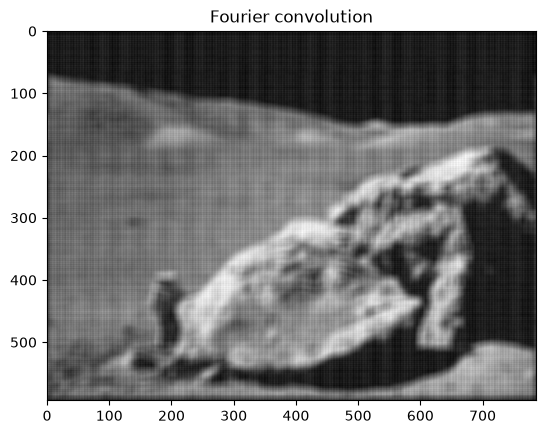

In [16]:
rows, cols = img.shape
kernel_padded = np.zeros((rows, cols), np.float32)
kh, kw = kernel.shape
kernel_padded[:kh, :kw] = kernel

kernel_padded = np.roll(kernel_padded, -kh // 2, axis=0)
kernel_padded = np.roll(kernel_padded, -kw // 2, axis=1)

dft_img = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)

dft_kernel = cv.dft(kernel_padded, flags=cv.DFT_COMPLEX_OUTPUT)

dft_result = cv.mulSpectrums(dft_img, dft_kernel, 0)

img_conv_fourier = cv.idft(dft_result)
img_conv_fourier = cv.magnitude(img_conv_fourier[:,:,0], img_conv_fourier[:,:,1])

plt.imshow(img_conv_fourier, cmap="gray")
plt.title("Fourier convolution")
plt.show()

In [17]:
print("свертка через Фурье размыла изображение, но не весь шум убран")

свертка через Фурье размыла изображение, но не весь шум убран


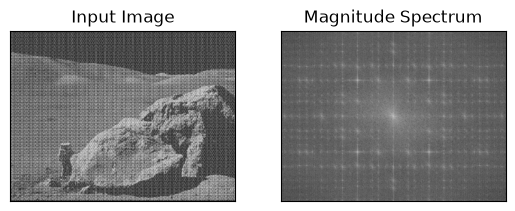

In [9]:
dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

magnitude_spectrum = 20 * np.log(cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1]))

plt.subplot(121), plt.imshow(img, cmap="gray")
plt.title("Input Image"), plt.xticks([]), plt.yticks([])

plt.subplot(122), plt.imshow(magnitude_spectrum, cmap="gray")
plt.title("Magnitude Spectrum"), plt.xticks([]), plt.yticks([])

plt.show()

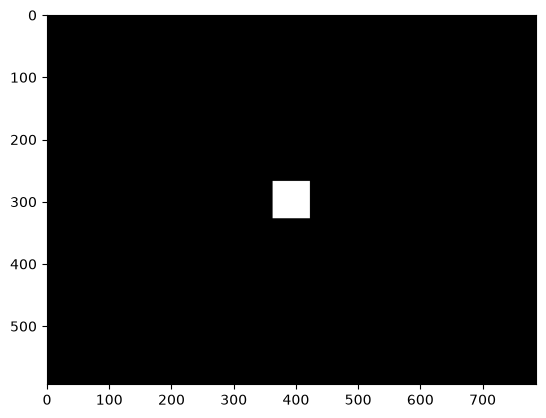

In [10]:
mask = np.zeros((img.shape[0], img.shape[1], 2), np.uint8)
centerX, centerY = (int(img.shape[0] / 2)), (int(img.shape[1] / 2))
mask[centerX - 30:centerX + 30, centerY - 30:centerY + 30] = 1

plt.imshow(mask[:,:,0], cmap="gray")
plt.show()

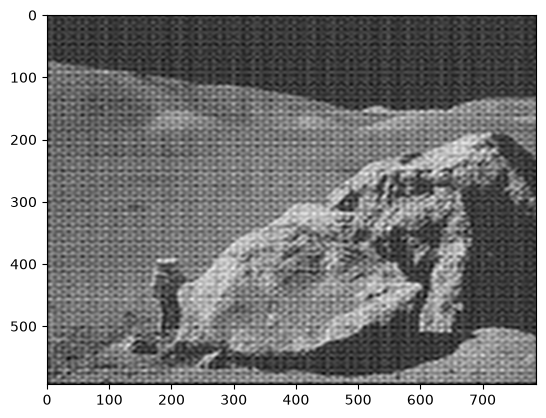

In [28]:
f_ishift = np.fft.ifftshift(dft_shift)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0], img_back[:,:,1])

plt.imshow(img_back, cmap="gray")

plt.show()

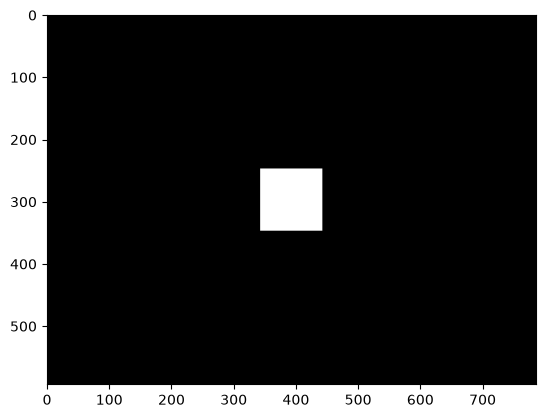

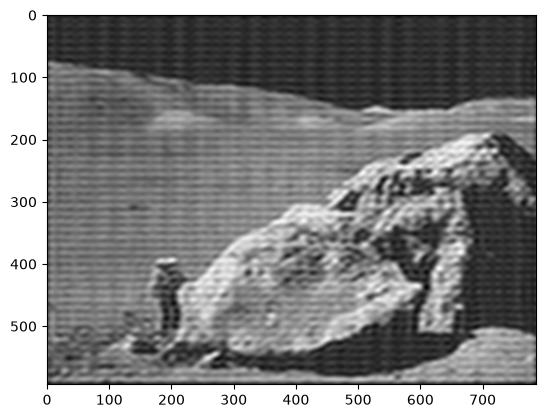

In [18]:
mask = np.zeros((img.shape[0], img.shape[1], 2), np.uint8)
centerX, centerY = (int(img.shape[0] / 2)), (int(img.shape[1] / 2))
mask[centerX - 50:centerX + 50, centerY - 50:centerY + 50] = 1

plt.imshow(mask[:,:,0], cmap='gray')
plt.show()

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
dft_shift = dft_shift * mask

f_ishift = np.fft.ifftshift(dft_shift)
img_back_big = cv.idft(f_ishift)
img_back_big = cv.magnitude(img_back_big[:,:,0], img_back_big[:,:,1])

plt.imshow(img_back_big, cmap='gray')
plt.show()

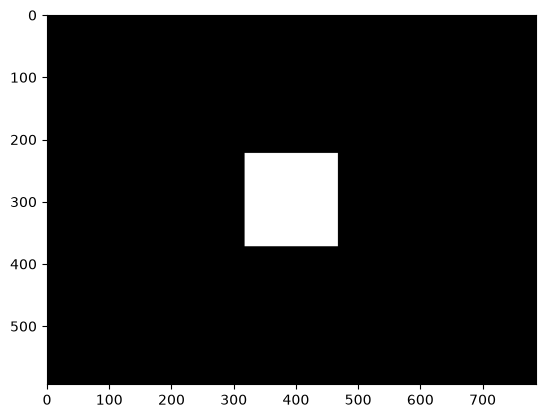

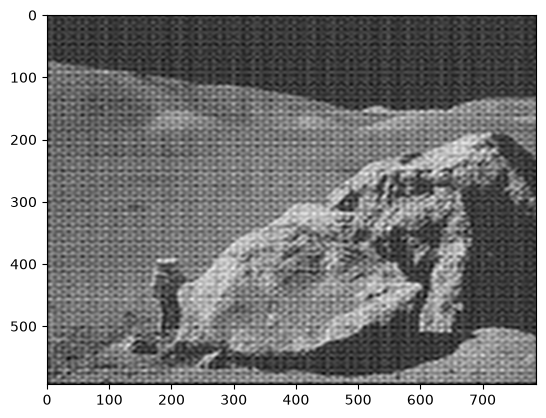

In [23]:
mask = np.zeros((img.shape[0], img.shape[1], 2), np.uint8)
centerX, centerY = (int(img.shape[0] / 2)), (int(img.shape[1] / 2))
mask[centerX - 75:centerX + 75, centerY - 75:centerY + 75] = 1

plt.imshow(mask[:,:,0], cmap='gray')
plt.show()

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
dft_shift = dft_shift * mask

f_ishift = np.fft.ifftshift(dft_shift)
img_back_very_big = cv.idft(f_ishift)
img_back_very_big = cv.magnitude(img_back_very_big[:,:,0], img_back_very_big[:,:,1])

plt.imshow(img_back_very_big, cmap='gray')
plt.show()

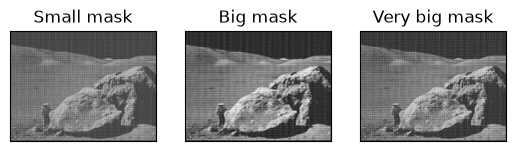

In [25]:
plt.subplot(131), plt.imshow(img_back, cmap="gray")
plt.title("Small mask"), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(img_back_big, cmap="gray")
plt.title("Big mask"), plt.xticks([]), plt.yticks([])

plt.subplot(133), plt.imshow(img_back_very_big, cmap="gray")
plt.title("Very big mask"), plt.xticks([]), plt.yticks([])

plt.show()

In [29]:
print("лучше всех отработала маска (100x100")

лучше всех отработала маска (100x100
